In [1]:
import numpy as np
import torch
import torchvision.transforms.functional as F
from pathlib import Path
import sys
# Add project directories so local modules import correctly
repo_root = Path.cwd()
for p in (repo_root / "04_modeling", repo_root / "03_datapreparation"):
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.append(p_str)
# Models
from models.unet import UNet
from models.deeplab import DeepLabV3Plus
# Dataset, DataLoader and Transforms
from cityscapes_dataset import CityscapesDataset
from torch.utils.data import DataLoader
from pathlib import Path
import torchvision.transforms.functional as F
from PIL import Image
# For visualization
import matplotlib.pyplot as plt

In [3]:
# Cityscapes 20 class colors (R,G,B) based on trainId
CITYSCAPES_COLORS = np.array([
    [128, 64,128],  # 0: road
    [244, 35,232],  # 1: sidewalk
    [250,170,160],  # 2: parking
    [230,150,140],  # 3: rail track
    [ 70, 70, 70],  # 4: building
    [180,165,180],  # 5: guard rail
    [153,153,153],  # 6: pole
    [250,170, 30],  # 7: traffic light
    [220,220,  0],  # 8: traffic sign
    [107,142, 35],  # 9: vegetation
    [152,251,152],  # 10: terrain
    [ 70,130,180],  # 11: sky
    [220, 20, 60],  # 12: person
    [255,  0,  0],  # 13: rider
    [  0,  0,142],  # 14: car
    [  0,  0, 70],  # 15: truck
    [  0, 60,100],  # 16: bus
    [  0, 80,100],  # 17: train
    [  0,  0,230],  # 18: motorcycle
    [119, 11, 32],  # 19: bicycle
], dtype=np.uint8)

def label_to_color(label):
    h, w = label.shape
    color_image = np.zeros((h, w, 3), dtype=np.uint8)
    for class_idx, color in enumerate(CITYSCAPES_COLORS):
        mask = label == class_idx
        color_image[mask] = color

    # Set ignore_index to black
    mask = label == 255
    color_image[mask] = [0, 0, 0]
    return color_image

Epoch 199
Train Loss 0.06996467659870784
Train Accuracy 0.9596164226531982
Train MIoU 0.6942357507803419
Val Loss 0.15436224887768427
Val Accuracy 0.9292846322059631
Val MIoU 0.5089366528013779


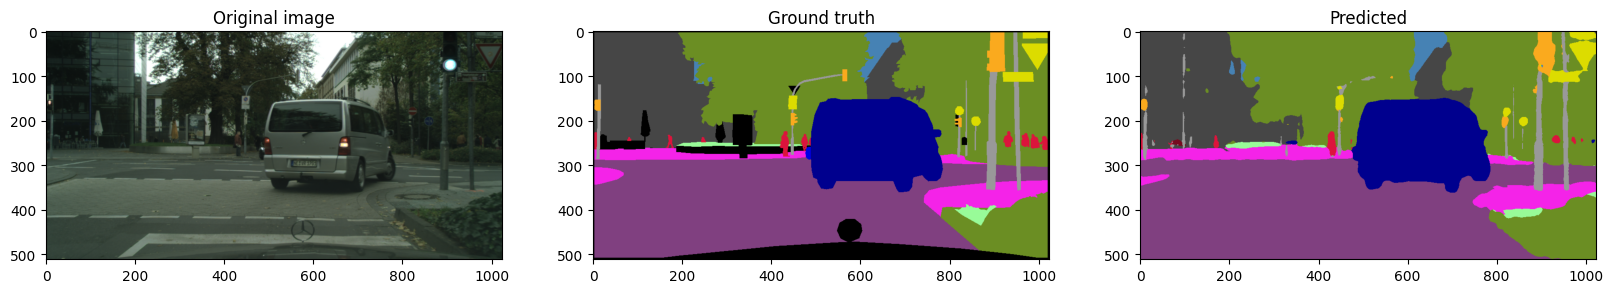

In [16]:
checkpoint = torch.load("./checkpoints/deeplab_cityscapes_3258105/best_deeplab_cityscapes_3258105.pth", weights_only=False)
print(f"Epoch {checkpoint['epoch']}")
print(f"Train Loss {checkpoint['train_loss']}")
print(f"Train Accuracy {checkpoint['train_acc']}")
print(f"Train MIoU {checkpoint['train_miou']}")
print(f"Val Loss {checkpoint['val_loss']}")
print(f"Val Accuracy {checkpoint['val_acc']}")
print(f"Val MIoU {checkpoint['val_miou']}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

height, width = 512, 1024
def image_transform(image):
    image = Image.fromarray(image)  # numpy -> PIL
    image = F.resize(image, (height, width), interpolation=F.InterpolationMode.BILINEAR) # Bilinear for RGB-Images
    image = F.pil_to_tensor(image).float() / 255.0  # Scaling
    return image


def label_transform(label):
    label = Image.fromarray(label)  # numpy -> PIL
    label = F.resize(label, (height, width), interpolation=F.InterpolationMode.NEAREST) # Nearest Neighbor for Labels
    label = F.pil_to_tensor(label).long().squeeze()  # PIL -> LongTensor no Scaling, squeeze() to remove channel dimension
    return label


# Define data paths
data_dir = Path("./data/cityscapes_intersections_heading/fine_intersections_3")
image_dir = data_dir / "leftImg8bit_trainvaltest/leftImg8bit"
label_dir = data_dir / "gtFine_trainvaltest/gtFine"

# Initialize datasets
train_dataset = CityscapesDataset(image_dir, label_dir, split="train", image_transform=image_transform, label_transform=label_transform)
val_dataset = CityscapesDataset(image_dir, label_dir, split="val", image_transform=image_transform, label_transform=label_transform)

model = DeepLabV3Plus(num_classes=20)
model = model.to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

fig, axes = plt.subplots(1, 3, figsize=(20, 10))

with torch.no_grad():
    image, label = train_dataset[6]
    image = image.unsqueeze(0)
    image = image.to(device)

    prediction = model(image)
    prediction = prediction.squeeze(0)
    predicted = torch.argmax(prediction, dim=0).cpu().numpy()
    
    axes[0].imshow(image.squeeze(0).cpu().permute(1, 2, 0))
    axes[0].set_title("Original image")
    axes[1].imshow(label_to_color(label))
    axes[1].set_title("Ground truth")
    axes[2].imshow(label_to_color(predicted))
    axes[2].set_title("Predicted")
    plt.show()